In [ ]:
#Import

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [ ]:
# Load the CSV (local — sitting next to this notebook)
df = pd.read_csv("cleanedupcardataupdated_colors.csv").dropna().reset_index(drop=True)
print(f"Loaded {len(df):,} rows")


Loaded 642,445 rows


In [ ]:
# Filter out price outliers — billion-dollar typos and $1 placeholders
mask = (df["price"] >= 500) & (df["price"] <= 200_000)
df = df[mask].reset_index(drop=True)

print(f"Rows after filtering: {len(df):,}")
print(f"Price range: ${df['price'].min():,.0f} – ${df['price'].max():,.0f}")
print(f"Median: ${df['price'].median():,.0f}")

Rows after filtering: 641,406
Price range: $500 – $200,000
Median: $27,918


In [ ]:
# Target
y = df["price"].values.astype(float)

# Selecting the 4 numeric features
numeric_cols = ["year", "mileage", "accidents_or_damage", "one_owner"]
print("Rows:", len(df))
print("y shape:", y.shape)
print("Numeric features:", numeric_cols)


Rows: 641406
y shape: (641406,)
Numeric features: ['year', 'mileage', 'accidents_or_damage', 'one_owner']


In [ ]:
#Step 2: Build the design matrix X

#Select the 4 numeric columns out of df as a numpy array
X_features = df[numeric_cols].values.astype(float)

#Make a column of ones (n x 1)for the intercept
n = len(df)
ones = np.ones((n, 1))

#Stack
X = np.hstack([ones, X_features])

print("X_features shape:", X_features.shape)
print("X shape:          ", X.shape)

X_features shape: (641406, 4)
X shape:           (641406, 5)


In [ ]:
# Step 3: Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

print("Train:", X_train.shape, "→", y_train.shape)
print("Test: ", X_test.shape, "→", y_test.shape)

Train: (513124, 5) → (513124,)
Test:  (128282, 5) → (128282,)


In [ ]:
# Step 4: Solve the normal equation
# From Jax's equation: w = (X^T X)^-1 X^T y

XtX = X_train.T @ X_train
Xty = X_train.T @ y_train

w = np.linalg.solve(XtX, Xty)

print("\nLearned weights:")
for name, weight in zip(["intercept"] + numeric_cols, w):
    print(f"  {name:25s} {weight:>15,.2f}")



Learned weights:
  intercept                   -1,929,904.59
  year                               977.22
  mileage                             -0.16
  accidents_or_damage             -3,587.52
  one_owner                         -373.65


In [ ]:
#Step 5: Predicting on test set and score
y_pred = X_test @ w
residuals = y_test - y_pred

mse = np.mean(residuals ** 2)
rmse = np.sqrt(mse)
r2 = 1 - np.sum(residuals ** 2) / np.sum((y_test - y_test.mean())**2)

print(f"Test MSE:  {mse:,.2f}")
print(f"Test RMSE: ${rmse:,.2f}")
print(f"Test R²:   {r2:.4f}")

Test MSE:  260,753,473.72
Test RMSE: $16,147.86
Test R²:   0.2956


In [ ]:
# Step 6: Add categoricals via one-hot encoding

# Which categoricals to add (skip colors and model_cat for now)
categorical_cols = [
    "manufacturer_cat",
    "fuel_type_cat",
    "transmission_cat",
    "drivetrain_cat",
]

# One-hot encode them. drop_first=True drops one column per categorical
# to avoid the dummy variable trap (keeps X^T X invertible).
X_cat = pd.get_dummies(df[categorical_cols], drop_first=True).values.astype(float)

print("Numeric block:    ", X_features.shape)
print("Categorical block:", X_cat.shape)

# Build new X: intercept + numeric + categorical
X_full = np.hstack([np.ones((n, 1)), X_features, X_cat])
print("Full X shape:     ", X_full.shape)

Numeric block:     (641406, 4)
Categorical block: (641406, 35)
Full X shape:      (641406, 40)


In [ ]:
# Step 7: Retrain plain LS on X_full (numerics + categoricals)

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_full, y, test_size=0.2, random_state=1
)

w_full = np.linalg.solve(X_train_f.T @ X_train_f, X_train_f.T @ y_train_f)

y_pred_f    = X_test_f @ w_full
residuals_f = y_test_f - y_pred_f

mse_full  = np.mean(residuals_f**2)
rmse_full = np.sqrt(mse_full)
r2_full   = 1 - np.sum(residuals_f**2) / np.sum((y_test_f - y_test_f.mean())**2)

print(f"=== Plain LS with categoricals ({X_full.shape[1]} features) ===")
print(f"Test MSE:  {mse_full:,.2f}")
print(f"Test RMSE: ${rmse_full:,.2f}")
print(f"Test R²:   {r2_full:.4f}\n")

print(f"=== Comparison vs. baseline (4 numeric features) ===")
print(f"Baseline R²:        {r2:.4f}")
print(f"Now R²:             {r2_full:.4f}")
print(f"Baseline RMSE:      ${rmse:,.2f}")
print(f"Now RMSE:           ${rmse_full:,.2f}")
print(f"RMSE improvement:   ${rmse - rmse_full:,.2f} per car")

=== Plain LS with categoricals (40 features) ===
Test MSE:  168,767,956.60
Test RMSE: $12,991.07
Test R²:   0.5441

=== Comparison vs. baseline (4 numeric features) ===
Baseline R²:        0.2956
Now R²:             0.5441
Baseline RMSE:      $16,147.86
Now RMSE:           $12,991.07
RMSE improvement:   $3,156.79 per car


In [ ]:
# Recover feature names (we dropped them when we used .values earlier)
cat_df = pd.get_dummies(df[categorical_cols], drop_first=True)
feature_names = ["intercept"] + numeric_cols + list(cat_df.columns)

assert len(feature_names) == len(w_full), "Name/weight length mismatch!"

wdf = pd.DataFrame({"feature": feature_names, "weight": w_full})

# 1. Numeric features
print("=" * 65)
print("NUMERIC FEATURES")
print("=" * 65)
for name in ["intercept"] + numeric_cols:
    w = wdf.loc[wdf.feature == name, "weight"].iloc[0]
    print(f"  {name:30s} {w:>15,.2f}")

# 2. Categoricals — top positive and top negative
cat_only = wdf[~wdf.feature.isin(["intercept"] + numeric_cols)]

print("\n" + "=" * 65)
print("TOP 10 CATEGORICALS PUSHING PRICE UP")
print("=" * 65)
for _, row in cat_only.sort_values("weight", ascending=False).head(10).iterrows():
    print(f"  {row['feature']:35s} +${row['weight']:>12,.2f}")

print("\n" + "=" * 65)
print("TOP 10 CATEGORICALS PUSHING PRICE DOWN")
print("=" * 65)
for _, row in cat_only.sort_values("weight", ascending=True).head(10).iterrows():
    print(f"  {row['feature']:35s} ${row['weight']:>13,.2f}")

NUMERIC FEATURES
  intercept                        -2,149,216.96
  year                                  1,091.56
  mileage                                  -0.14
  accidents_or_damage                  -2,655.62
  one_owner                               694.53

TOP 10 CATEGORICALS PUSHING PRICE UP
  manufacturer_cat_Porsche            +$   40,022.91
  manufacturer_cat_Land Rover         +$   16,822.19
  manufacturer_cat_Mercedes-Benz      +$   13,091.59
  manufacturer_cat_Cadillac           +$    8,790.50
  manufacturer_cat_Tesla              +$    8,602.71
  manufacturer_cat_Lexus              +$    6,878.66
  manufacturer_cat_BMW                +$    6,405.39
  manufacturer_cat_GMC                +$    6,368.14
  drivetrain_cat_4WD                  +$    6,239.66
  transmission_cat_manual             +$    5,719.73

TOP 10 CATEGORICALS PUSHING PRICE DOWN
  fuel_type_cat_e85                   $   -20,378.64
  fuel_type_cat_gasoline              $   -19,130.80
  fuel_type_cat_hybrid  

In [ ]:
# Filter rare model_cat values — lump into "Other" if too few listings
MIN_COUNT = 10

model_counts = df["model_cat"].value_counts()
common_models = model_counts[model_counts >= MIN_COUNT].index

df["model_cat_filt"] = df["model_cat"].where(df["model_cat"].isin(common_models), "Other")

print(f"Original model_cat levels: {df['model_cat'].nunique()}")
print(f"Keeping {len(common_models)} (≥{MIN_COUNT} listings each), lumping the rest")
print(f"Rows lumped into 'Other': {(df['model_cat_filt'] == 'Other').sum():,}")

Original model_cat levels: 666
Keeping 543 (≥10 listings each), lumping the rest
Rows lumped into 'Other': 454


In [ ]:
# Step 8: Extended categoricals — filtered model_cat + colors
categorical_cols_ext = [
    "manufacturer_cat",
    "fuel_type_cat",
    "transmission_cat",
    "drivetrain_cat",
    "model_cat_filt",   # filtered (≥50 listings per model, rest lumped into "Other")
    "exterior_color",   # NEW — likely low signal, but useful for the Lasso story later
    "interior_color",   # NEW
]

X_cat_ext = pd.get_dummies(df[categorical_cols_ext], drop_first=True).values.astype(float)

print(f"Numeric block:      {X_features.shape}")
print(f"Categorical block:  {X_cat_ext.shape}")

X_full_ext = np.hstack([np.ones((n, 1)), X_features, X_cat_ext])
print(f"Full X shape:       {X_full_ext.shape}")


Numeric block:      (641406, 4)
Categorical block:  (641406, 602)
Full X shape:       (641406, 607)


In [ ]:
# Step 9: Retrain plain LS with model_cat + colors
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_full_ext, y, test_size=0.2, random_state=1
)

# NOTE: Adding model_cat alongside manufacturer creates structural collinearity
# (every model belongs to exactly one manufacturer — they're nested categoricals).
# This makes X^T X rank-deficient, and np.linalg.solve refuses. np.linalg.lstsq
# solves the SAME least-squares problem min ||y - Xw||^2 but via SVD, which
# handles rank deficiency cleanly. Same math, more robust algorithm.

print(f"Solving on {X_train_e.shape[1]} features via SVD-based lstsq...")
w_full_ext, _, rank, _ = np.linalg.lstsq(X_train_e, y_train_e, rcond=None)
print(f"Done. Matrix rank: {rank} / {X_train_e.shape[1]} columns")
print(f"Rank deficit (linearly dependent columns): {X_train_e.shape[1] - rank}")

# Test metrics
y_pred_e    = X_test_e @ w_full_ext
residuals_e = y_test_e - y_pred_e
mse_e  = np.mean(residuals_e**2)
rmse_e = np.sqrt(mse_e)
r2_e   = 1 - np.sum(residuals_e**2) / np.sum((y_test_e - y_test_e.mean())**2)

# Training R² — to see if overfitting starts
y_train_pred_e = X_train_e @ w_full_ext
r2_train_e = 1 - np.sum((y_train_e - y_train_pred_e)**2) / np.sum((y_train_e - y_train_e.mean())**2)

print(f"\n=== Plain LS with model_cat + colors ({X_full_ext.shape[1]} features) ===")
print(f"Train R²:  {r2_train_e:.4f}")
print(f"Test R²:   {r2_e:.4f}")
print(f"Test RMSE: ${rmse_e:,.2f}")

print(f"\n=== Comparison across models ===")
print(f"4 numeric only:                  R² = {r2:.4f}     RMSE = ${rmse:,.2f}")
print(f"40 features (no model_cat):      R² = {r2_full:.4f}     RMSE = ${rmse_full:,.2f}")
print(f"~{X_full_ext.shape[1]} features (full):           R² = {r2_e:.4f}     RMSE = ${rmse_e:,.2f}")


# Ridge Regression

Same design matrix `X_full_ext` (~498 features), now with an L2 penalty.
Closed form: **w = (XᵀX + λI)⁻¹ Xᵀy**


In [ ]:
# Ridge solver from scratch
def ridge_solve(X, y, lam):
    """Closed-form Ridge regression: w = (X^T X + lam*I)^-1 X^T y"""
    n_features = X.shape[1]
    I = np.eye(n_features)
    # Don't penalize the intercept (column 0) — by convention you let it float
    I[0, 0] = 0
    return np.linalg.solve(X.T @ X + lam * I, X.T @ y)

# Sanity check: tiny lambda should reproduce plain LS
w_ridge_small = ridge_solve(X_train_e, y_train_e, lam=0.01)
y_pred_check  = X_test_e @ w_ridge_small
r2_check = 1 - np.sum((y_test_e - y_pred_check)**2) / np.sum((y_test_e - y_test_e.mean())**2)
print(f"Ridge (lam=0.01) R²: {r2_check:.4f}")
print(f"Plain LS         R²: {r2_e:.4f}   (should match within ~0.0001)")


Ridge (lam=0.01) R²: 0.7850
Plain LS         R²: 0.7850   (should match within ~0.0001)


In [ ]:
# Sweep lambda over many orders of magnitude
lambdas = np.logspace(-3, 6, 19)

ridge_results = []
for lam in lambdas:
    w_r = ridge_solve(X_train_e, y_train_e, lam)
    y_train_pred = X_train_e @ w_r
    y_test_pred  = X_test_e  @ w_r
    r2_train  = 1 - np.sum((y_train_e - y_train_pred)**2) / np.sum((y_train_e - y_train_e.mean())**2)
    r2_test   = 1 - np.sum((y_test_e  - y_test_pred )**2) / np.sum((y_test_e  - y_test_e.mean() )**2)
    rmse_test = np.sqrt(np.mean((y_test_e - y_test_pred)**2))
    ridge_results.append({
        "lambda": lam, "r2_train": r2_train, "r2_test": r2_test,
        "rmse_test": rmse_test,
        "max_abs_w":  np.abs(w_r[1:]).max(),
        "mean_abs_w": np.abs(w_r[1:]).mean(),
    })

ridge_df = pd.DataFrame(ridge_results)
print(ridge_df.to_string(index=False, formatters={
    "lambda":     lambda x: f"{x:>12.4g}",
    "r2_train":   lambda x: f"{x:.4f}",
    "r2_test":    lambda x: f"{x:.4f}",
    "rmse_test":  lambda x: f"${x:,.2f}",
    "max_abs_w":  lambda x: f"{x:,.1f}",
    "mean_abs_w": lambda x: f"{x:,.2f}",
}))

best_ridge = ridge_df.loc[ridge_df["r2_test"].idxmax()]
print(f"\nBest λ by test R²: {best_ridge['lambda']:.4g}")
print(f"  Test R²:    {best_ridge['r2_test']:.4f}")
print(f"  Test RMSE:  ${best_ridge['rmse_test']:,.2f}")


      lambda r2_train r2_test  rmse_test max_abs_w mean_abs_w
       0.001   0.7835  0.7850  $8,920.67 152,819.1  19,069.57
    0.003162   0.7835  0.7850  $8,920.78 151,782.5  18,552.71
        0.01   0.7835  0.7850  $8,921.08 149,155.7  17,323.46
     0.03162   0.7835  0.7850  $8,921.68 144,262.6  15,404.34
         0.1   0.7835  0.7850  $8,922.46 138,222.9  13,646.25
      0.3162   0.7835  0.7849  $8,923.48 132,074.9  12,184.17
           1   0.7833  0.7848  $8,925.71 124,249.1  11,093.05
       3.162   0.7830  0.7845  $8,932.74 110,188.9  10,142.83
          10   0.7818  0.7832  $8,959.50  84,743.8   8,974.65
       31.62   0.7779  0.7792  $9,040.24  74,528.3   7,438.25
         100   0.7682  0.7698  $9,230.46  54,314.3   5,702.82
       316.2   0.7469  0.7496  $9,628.17  38,178.4   3,986.66
        1000   0.7078  0.7116 $10,333.09  29,135.9   2,517.90
        3162   0.6461  0.6506 $11,373.91  22,947.0   1,411.35
       1e+04   0.5655  0.5706 $12,607.36  13,960.4     708.12
   3.162

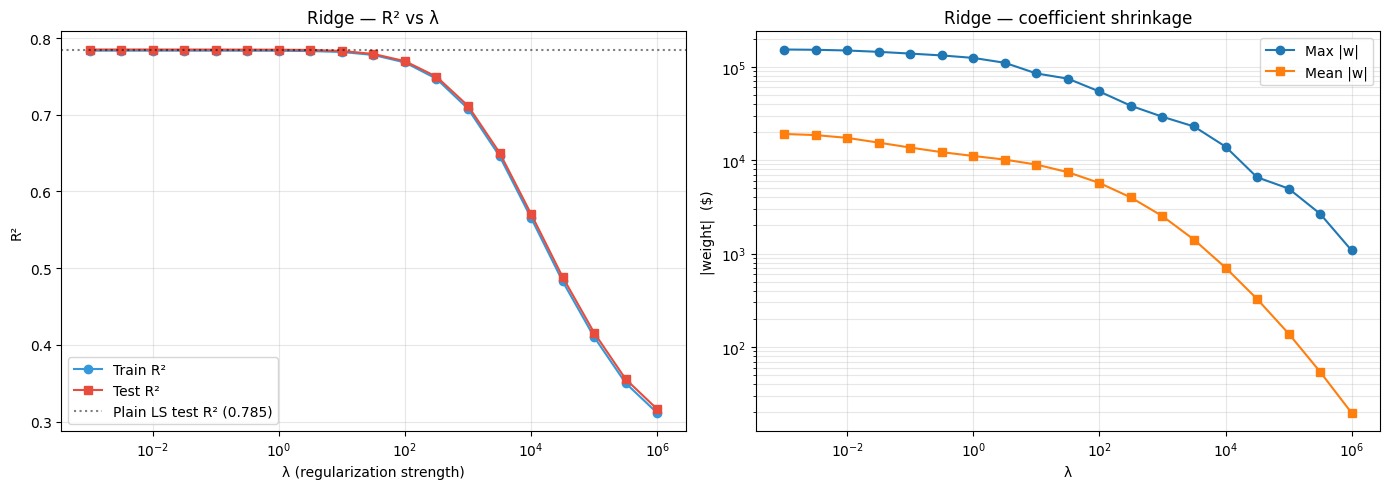

In [ ]:
# Ridge diagnostic plot — R² and shrinkage vs lambda
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogx(ridge_df["lambda"], ridge_df["r2_train"], "o-", label="Train R²", color="#3498db")
axes[0].semilogx(ridge_df["lambda"], ridge_df["r2_test"],  "s-", label="Test R²",  color="#e74c3c")
axes[0].axhline(r2_e, color="black", linestyle=":", alpha=0.5, label=f"Plain LS test R² ({r2_e:.3f})")
axes[0].set_xlabel("λ (regularization strength)")
axes[0].set_ylabel("R²")
axes[0].set_title("Ridge — R² vs λ")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].loglog(ridge_df["lambda"], ridge_df["max_abs_w"],  "o-", label="Max |w|")
axes[1].loglog(ridge_df["lambda"], ridge_df["mean_abs_w"], "s-", label="Mean |w|")
axes[1].set_xlabel("λ")
axes[1].set_ylabel("|weight|  ($)")
axes[1].set_title("Ridge — coefficient shrinkage")
axes[1].legend()
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.savefig("ridge_sweep.png", dpi=120, bbox_inches="tight")
plt.show()


# Lasso Regression

L1 penalty: `min (1/2n)||y - Xw||² + λ ||w||₁`

No closed form (the absolute-value penalty isn't differentiable at zero), so we use `sklearn.linear_model.LassoCV`, which uses coordinate descent + cross-validation to pick λ. Lasso's superpower vs Ridge: it drives many coefficients to *exactly* zero — automatic feature selection.


In [ ]:
# Memory-safe LassoCV — subsample + single-threaded + float32
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# Subsample the training data — 100k rows is plenty for LassoCV
np.random.seed(1)
SUBSAMPLE = 100_000
sub_idx = np.random.choice(len(X_train_e), size=SUBSAMPLE, replace=False)

X_train_sub = X_train_e[sub_idx, 1:].astype(np.float32)   # drop intercept, halve dtype
y_train_sub = y_train_e[sub_idx].astype(np.float32)

# Test set can stay full for honest evaluation
X_test_l = X_test_e[:, 1:].astype(np.float32)

# Standardize
scaler = StandardScaler()
X_train_sub_scaled = scaler.fit_transform(X_train_sub)
X_test_l_scaled    = scaler.transform(X_test_l)

print(f"Training on {SUBSAMPLE:,} rows × {X_train_sub_scaled.shape[1]} features")
print(f"X memory: {X_train_sub_scaled.nbytes / 1e6:.1f} MB (vs ~2,000 MB before)")

print("\nRunning LassoCV (single-threaded, smaller grid)...")
lasso_cv = LassoCV(
    cv=3,
    n_alphas=10,
    max_iter=2000,
    n_jobs=1,       # CRITICAL: single worker — prevents RAM-multiplying parallelism
    tol=1e-3,
)
lasso_cv.fit(X_train_sub_scaled, y_train_sub)
print(f"Done. Selected lambda: {lasso_cv.alpha_:.4g}\n")

# Evaluate on full untouched test set
y_pred_lasso = lasso_cv.predict(X_test_l_scaled)
r2_lasso   = 1 - np.sum((y_test_e - y_pred_lasso)**2) / np.sum((y_test_e - y_test_e.mean())**2)
rmse_lasso = np.sqrt(np.mean((y_test_e - y_pred_lasso)**2))

n_features = len(lasso_cv.coef_)
n_zero     = (lasso_cv.coef_ == 0).sum()
n_kept     = n_features - n_zero

print(f"Test R²:    {r2_lasso:.4f}")
print(f"Test RMSE:  ${rmse_lasso:,.2f}")
print(f"Features kept (non-zero): {n_kept}/{n_features} ({100*n_kept/n_features:.1f}%)")
print(f"Features pruned (zero):   {n_zero}/{n_features} ({100*n_zero/n_features:.1f}%)")


Training on 100,000 rows × 606 features
X memory: 242.4 MB (vs ~2,000 MB before)

Running LassoCV (single-threaded, smaller grid)...


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:1663: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


Done. Selected lambda: 9.837

Test R²:    0.7836
Test RMSE:  $8,949.72
Features kept (non-zero): 552/606 (91.1%)
Features pruned (zero):   54/606 (8.9%)


In [ ]:
# Which features survived Lasso's axe? Broken down by category.
# Regenerate cat_df_ext to recover the column names (we used .values in Cell 12 and lost them)
cat_df_ext = pd.get_dummies(df[categorical_cols_ext], drop_first=True)

all_feature_names = numeric_cols + list(cat_df_ext.columns)
assert len(all_feature_names) == len(lasso_cv.coef_), \
    f"Length mismatch: {len(all_feature_names)} names vs {len(lasso_cv.coef_)} coefs"

lasso_w = pd.DataFrame({"feature": all_feature_names, "weight": lasso_cv.coef_})
lasso_w["kept"] = lasso_w["weight"] != 0

color = lasso_w[lasso_w["feature"].str.startswith(("exterior_color", "interior_color"))]
model = lasso_w[lasso_w["feature"].str.startswith("model_cat_filt")]
mfr   = lasso_w[lasso_w["feature"].str.startswith("manufacturer_cat")]

print(f"{'Category':25s} {'Total':>8s} {'Kept':>8s} {'Pruned':>8s} {'% kept':>10s}")
print("-" * 65)
for name, subset in [("Colors", color), ("Models (filtered)", model),
                     ("Manufacturers", mfr), ("All non-numeric", lasso_w[4:])]:
    total = len(subset); kept = subset["kept"].sum()
    print(f"{name:25s} {total:>8d} {kept:>8d} {total-kept:>8d} {100*kept/total:>9.1f}%")

# Top 20 features Lasso kept (by absolute standardized weight)
top_kept = (lasso_w[lasso_w["kept"]]
            .reindex(lasso_w["weight"].abs().sort_values(ascending=False).index)
            .head(20))
print("\n=== TOP 20 FEATURES KEPT BY LASSO (standardized weights) ===")
for _, row in top_kept.iterrows():
    sign = "+" if row["weight"] >= 0 else ""
    print(f"  {row['feature']:55s} {sign}{row['weight']:>10,.2f}")


Category                     Total     Kept   Pruned     % kept
-----------------------------------------------------------------
Colors                          24       21        3      87.5%
Models (filtered)              543      500       43      92.1%
Manufacturers                   29       22        7      75.9%
All non-numeric                602      548       54      91.0%

=== TOP 20 FEATURES KEPT BY LASSO (standardized weights) ===
  year                                                    +  5,747.66
  mileage                                                  -5,264.45
  manufacturer_cat_Porsche                                +  4,068.66
  fuel_type_cat_gasoline                                   -3,428.55
  model_cat_filt_AMG                                      +  2,910.67
  model_cat_filt_Escalade                                 +  2,437.62
  model_cat_filt_911                                      +  2,237.94
  model_cat_filt_G-Class                                  +  2,1

# Three-way comparison: Plain LS vs Ridge vs Lasso


In [ ]:
# Final comparison table
comparison = pd.DataFrame([
    {"Model": "Plain LS",         "Test R²": r2_e,                "Test RMSE": rmse_e,                "Features used": f"{X_full_ext.shape[1]} / {X_full_ext.shape[1]} (all)"},
    {"Model": f"Ridge (λ={best_ridge['lambda']:.3g})", "Test R²": best_ridge["r2_test"], "Test RMSE": best_ridge["rmse_test"], "Features used": f"{X_full_ext.shape[1]} / {X_full_ext.shape[1]} (all, shrunk)"},
    {"Model": f"Lasso (λ={lasso_cv.alpha_:.3g})",      "Test R²": r2_lasso,             "Test RMSE": rmse_lasso,             "Features used": f"{n_kept} / {n_features} (pruned {n_zero})"},
])

print(comparison.to_string(index=False, formatters={
    "Test R²":   lambda x: f"{x:.4f}",
    "Test RMSE": lambda x: f"${x:,.2f}",
}))


          Model Test R² Test RMSE           Features used
       Plain LS  0.7850 $8,920.61         607 / 607 (all)
Ridge (λ=0.001)  0.7850 $8,920.67 607 / 607 (all, shrunk)
 Lasso (λ=9.84)  0.7836 $8,949.72   552 / 606 (pruned 54)
